# 04timemap: radial time-space maps of Spain (1985 to 2026)

**What it does:** redraws Spain so that distance on the map means travel time by train, for every era and from every city.

- **Radial map.** One city is the centre. Every other city keeps its true compass bearing from the centre, and its distance from the centre is its travel time by train, converted to kilometres with one fixed scale for all eras. Times from the centre are therefore exact; times between two other cities are not shown by the map.
- **Why not MDS.** MDS on all 496 city pairs was tried first (see `progress_lpf3.md`, 19 Nov 2026). Spain's network is radial: most trips between two outer cities pass through Madrid, which no flat map can show. MDS missed Madrid times by a median of 70 to 100 min and squeezed Galicia next to Madrid. The radial map keeps the outline readable and the times exact. Bearings are kept, so no Procrustes rotation is needed: the only free choice is the scale, fitted once on 1985.
- **Main story:** Madrid at the centre. The page will also let the reader click any city to redraw the map around it, using the full 32 x 32 table.

**Input:** `data/clean/cities.csv` (01cities), `data/clean/shortcut_<era>.csv` (03shortcut), `data/raw/manual/access_2025.csv` (hand-made: how each city's fastest 2025 route from Madrid uses the high-speed network, with the train and its stops as evidence).

**Groups (access in 2025):** *full* = direct AVE from Madrid; *part* = the fastest train runs on high-speed track for part of the trip and on the conventional line for the rest (mostly Alvia; Teruel with a change at Zaragoza); *none* = conventional line all the way. Read from the Renfe GTFS of 18 Dec 2025, day Wed 14 Jan 2026. This replaces the provisional groups in `cities.csv` (16 Nov).

**Output:** `data/clean/timemap_positions.csv` (every era, centre and city: time, bearing, map position and real position in km), `data/clean/timemap_madrid.csv` (time from Madrid per city and era, and its share of 1985), `figures/04timemap.png`, `figures/04shrink.png`.

**Data credit:** travel times from 03shortcut: Renfe open GTFS (2025, 2026), FFE Biblioteca Ferroviaria timetable guides (1985, 1993, 2001), and hand-compiled backcasts (2010, 2018); see `progress_lpf3.md`.

## 0. Settings

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CITIES_CSV = Path("data") / "clean" / "cities.csv"
ACCESS_CSV = Path("data") / "raw" / "manual" / "access_2025.csv"
CLEAN_DIR = Path("data") / "clean"
FIG_DIR = Path("figures")
ERAS = ["1985", "1993", "2001", "2010", "2018", "2025", "2026"]  # <- eras, in order
MAIN_CENTRE = "Madrid"  # <- centre of the main story
SCALE_ERA = "1985"  # <- the scale (km per minute) is fitted on this era, from MAIN_CENTRE, and then kept for all eras
KM_PER_MIN = None  # <- None = fit on SCALE_ERA; or a number to fix the scale by hand
EARTH_RADIUS_KM = 6371.0
STORY_ERA = "2025"  # <- end of the main story (2026 is the slowdown frame)
ACCESS_ORDER = ["full", "part", "none"]
ACCESS_LABEL = {"hub": "Madrid", "full": "high-speed all the way", "part": "high-speed part of the way", "none": "no high-speed"}  # <- names used in tables and figures
COLOUR = {"hub": "#3a3a3a", "full": "#1d6fa5", "part": "#b8860b", "none": "#c2410c"}  # <- VISUAL: dot colours by access group (validated set: blue, ochre, orange red)
REAL_COLOUR = "#c4c4c4"  # <- VISUAL: real positions
MOVE_COLOUR = "#e8c49f"  # <- VISUAL: line from real to time position
FIG_EXTENT_KM = 620  # <- VISUAL: half width of each map panel

## 1. Read the cities and the travel-time tables

In [2]:
cities = pd.read_csv(CITIES_CSV, dtype={"main_stop_id": str, "stop_ids": str})
names = list(cities["city"])
access_table = pd.read_csv(ACCESS_CSV)
unknown = sorted(set(access_table["city"]) - set(names))
not_listed = sorted(set(names) - set(access_table["city"]) - {MAIN_CENTRE})
bad_value = sorted(set(access_table["access"]) - set(ACCESS_ORDER))
print(f"access file: {len(access_table)} cities; unknown names {unknown}; cities not listed {not_listed}; unknown access values {bad_value}")
group = dict(zip(access_table["city"], access_table["access"]))
group[MAIN_CENTRE] = "hub"
print(access_table["access"].value_counts().reindex(ACCESS_ORDER).to_string())

times = {}
for era in ERAS:
    table = pd.read_csv(CLEAN_DIR / f"shortcut_{era}.csv", index_col=0)
    table = table.reindex(index=names, columns=names)
    times[era] = table
    missing = int(table.isna().sum().sum())
    asymmetric = float((table - table.T).abs().max().max())
    print(f"{era}: {len(table)} cities, missing times {missing}, largest asymmetry {asymmetric:.0f} min")

access file: 31 cities; unknown names []; cities not listed []; unknown access values []
access
full    21
part     9
none     1
1985: 32 cities, missing times 0, largest asymmetry 0 min
1993: 32 cities, missing times 0, largest asymmetry 0 min
2001: 32 cities, missing times 0, largest asymmetry 0 min
2010: 32 cities, missing times 0, largest asymmetry 0 min
2018: 32 cities, missing times 0, largest asymmetry 0 min
2025: 32 cities, missing times 0, largest asymmetry 0 min
2026: 32 cities, missing times 0, largest asymmetry 0 min


## 2. Real geography seen from each centre

An azimuthal equidistant projection centred on the centre city keeps the true bearing and the true distance from that city to every other one, which is exactly what a radial time map needs. Over Spain the error for other pairs is small.

In [3]:
def from_centre(lat0, lon0, lat, lon):
    """Bearing (degrees from north, clockwise) and great-circle distance (km) from (lat0, lon0)."""
    p0 = np.radians(lat0)
    p1 = np.radians(lat)
    dl = np.radians(lon - lon0)
    y = np.sin(dl) * np.cos(p1)
    x = np.cos(p0) * np.sin(p1) - np.sin(p0) * np.cos(p1) * np.cos(dl)
    bearing = np.degrees(np.arctan2(y, x)) % 360
    h = np.sin((p1 - p0) / 2) ** 2 + np.cos(p0) * np.cos(p1) * np.sin(dl / 2) ** 2
    distance = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(h))
    return bearing, distance

lat = cities["lat"].to_numpy()
lon = cities["lon"].to_numpy()
geo = {}
for i, centre in enumerate(names):
    bearing, distance = from_centre(lat[i], lon[i], lat, lon)
    geo[centre] = pd.DataFrame({"city": names, "bearing": bearing, "real_km": distance})

print(geo[MAIN_CENTRE].sort_values("real_km").round(0).to_string(index=False))

         city  bearing  real_km
       Madrid      0.0      0.0
  Ciudad Real    187.0    159.0
   Valladolid    328.0    163.0
       Teruel     91.0    219.0
     Albacete    134.0    222.0
     Zaragoza     58.0    272.0
         León    328.0    290.0
         Jaén    182.0    292.0
      Córdoba    199.0    296.0
     Valencia    109.0    301.0
     Pamplona     31.0    317.0
       Bilbao     11.0    324.0
      Badajoz    240.0    328.0
    Santander    358.0    340.0
       Murcia    140.0    349.0
San Sebastián     23.0    353.0
     Alicante    129.0    358.0
      Granada    179.0    358.0
       Oviedo    332.0    375.0
       Lleida     68.0    387.0
      Sevilla    211.0    389.0
      Ourense    303.0    410.0
      Almería    164.0    411.0
       Málaga    189.0    416.0
    Tarragona     77.0    427.0
       Huelva    220.0    450.0
         Vigo    297.0    466.0
        Cádiz    208.0    487.0
     Santiago    306.0    488.0
    Barcelona     76.0    502.0
     A C

## 3. Scale: kilometres per minute

One scale for every era and every centre, so that a city closer to the centre on a later map really is quicker to reach. It is fitted so that the 1985 map from Madrid is as close as possible in size to the real map (least squares on the distances from Madrid). The scale is also an average speed: the straight-line speed of the 1985 network.

In [4]:
if KM_PER_MIN is None:
    t = times[SCALE_ERA].loc[MAIN_CENTRE].drop(MAIN_CENTRE)
    r = geo[MAIN_CENTRE].set_index("city")["real_km"].drop(MAIN_CENTRE)
    KM_PER_MIN = float((r * t).sum() / (t * t).sum())
print(f"Scale: 1 min = {KM_PER_MIN:.3f} km (a straight-line average of {KM_PER_MIN * 60:.0f} km/h in {SCALE_ERA})")

Scale: 1 min = 0.994 km (a straight-line average of 60 km/h in 1985)


## 4. Map positions for every era and centre

In [5]:
rows = []
for era in ERAS:
    for centre in names:
        g = geo[centre]
        minutes = times[era].loc[centre].to_numpy()
        angle = np.radians(g["bearing"].to_numpy())
        part = pd.DataFrame({"era": era, "centre": centre, "city": names})
        part["minutes"] = minutes
        part["bearing"] = g["bearing"].to_numpy()
        part["x_km"] = KM_PER_MIN * minutes * np.sin(angle)
        part["y_km"] = KM_PER_MIN * minutes * np.cos(angle)
        part["real_x_km"] = g["real_km"].to_numpy() * np.sin(angle)
        part["real_y_km"] = g["real_km"].to_numpy() * np.cos(angle)
        rows.append(part)
positions = pd.concat(rows, ignore_index=True)

# check: the distance from the centre on the map, divided by the scale, gives back the travel time
back = np.hypot(positions["x_km"], positions["y_km"]) / KM_PER_MIN
print(f"{len(positions)} rows; largest difference between map distance and travel time: {(back - positions['minutes']).abs().max():.6f} min")

7168 rows; largest difference between map distance and travel time: 0.000000 min


## 5. Checks

1. **How close is the 1985 map to the real one?** Distance between each city's time position and its real position, Madrid centre.
2. **What the map does not show.** On a radial map only times from the centre are exact. The distance between two other cities on the map is compared with their real travel time, to say honestly how far off it is.

In [6]:
madrid = positions[positions["centre"] == MAIN_CENTRE]
print("Distance from real position (km), Madrid centre:")
for era in ERAS:
    p = madrid[madrid["era"] == era]
    moved = np.hypot(p["x_km"] - p["real_x_km"], p["y_km"] - p["real_y_km"])
    print(f"  {era}: median {moved.median():4.0f}, largest {moved.max():4.0f} ({p.loc[moved.idxmax(), 'city']})")

print()
print("Times between two non-centre cities read off the Madrid map (min):")
others = [n for n in names if n != MAIN_CENTRE]
for era in ERAS:
    p = madrid[madrid["era"] == era].set_index("city")
    errors = []
    for i, a in enumerate(others):
        for b in others[i + 1:]:
            on_map = np.hypot(p.loc[a, "x_km"] - p.loc[b, "x_km"], p.loc[a, "y_km"] - p.loc[b, "y_km"]) / KM_PER_MIN
            errors.append(on_map - times[era].loc[a, b])
    errors = pd.Series(errors)
    print(f"  {era}: median error {errors.median():5.0f}, median absolute error {errors.abs().median():4.0f}, within 30 min {(errors.abs() <= 30).mean():.0%}")

Distance from real position (km), Madrid centre:
  1985: median   28, largest  199 (Teruel)
  1993: median   52, largest  245 (Sevilla)
  2001: median   62, largest  255 (Sevilla)
  2010: median  134, largest  345 (Barcelona)
  2018: median  161, largest  365 (Girona)
  2025: median  188, largest  365 (Girona)
  2026: median  186, largest  330 (Girona)

Times between two non-centre cities read off the Madrid map (min):
  1985: median error  -145, median absolute error  145, within 30 min 6%
  1993: median error  -125, median absolute error  125, within 30 min 7%
  2001: median error  -124, median absolute error  124, within 30 min 7%
  2010: median error  -109, median absolute error  109, within 30 min 6%
  2018: median error  -107, median absolute error  107, within 30 min 5%
  2025: median error  -103, median absolute error  103, within 30 min 6%
  2026: median error  -104, median absolute error  104, within 30 min 6%


**Reading the second check:** the map mostly draws two outer cities closer together than the train really is (negative errors), because the real trip between them usually goes through Madrid. That is the point of the radial view, and the page should say so in one line: "distances are exact from the centre city; click a city to see the map from there."

## 6. The Madrid story: who was pulled in, who was left behind

In [7]:
story = times[ERAS[0]].loc[MAIN_CENTRE].rename(ERAS[0]).to_frame()
for era in ERAS[1:]:
    story[era] = times[era].loc[MAIN_CENTRE]
story = story.drop(MAIN_CENTRE)
story.insert(0, "access", story.index.map(group))
for era in ERAS[1:]:
    story[f"share_{era}"] = (story[era] / story[ERAS[0]]).round(3)
story.index.name = "city"
story.to_csv(CLEAN_DIR / "timemap_madrid.csv", encoding="utf-8")

share = f"share_{STORY_ERA}"
print(f"Median time from Madrid as a share of {ERAS[0]}, by access group in 2025:")
summary = story.groupby("access")[[f"share_{e}" for e in ERAS[1:]]].median().round(2).reindex(ACCESS_ORDER)
summary.insert(0, "cities", story["access"].value_counts().reindex(ACCESS_ORDER))
print(summary.to_string())
print()
print(f"Most pulled in by {STORY_ERA}:")
print(story.sort_values(share).head(6)[["access", ERAS[0], STORY_ERA, share]].to_string())
print()
print(f"Least pulled in by {STORY_ERA}:")
print(story.sort_values(share).tail(6)[["access", ERAS[0], STORY_ERA, share]].to_string())
print()
change = (story["2026"] - story["2025"]).sort_values(ascending=False)
print("2026 against 2025 (min), largest changes:")
print(change[change.abs() >= 5].to_string())

Median time from Madrid as a share of 1985, by access group in 2025:
        cities  share_1993  share_2001  share_2010  share_2018  share_2025  share_2026
access                                                                                
full        21        0.89        0.85        0.50        0.43        0.40        0.44
part         9        0.89        0.89        0.70        0.71        0.69        0.69
none         1        1.09        1.10        0.98        0.98        0.98        1.13

Most pulled in by 2025:
           access   1985   2025  share_2025
city                                       
Tarragona    full  421.0  124.0       0.295
Valladolid   full  170.0   54.0       0.318
Barcelona    full  441.0  157.0       0.356
Málaga       full  439.0  159.0       0.362
Girona       full  571.0  208.0       0.364
Ourense      full  365.0  134.0       0.367

Least pulled in by 2025:
              access   1985   2025  share_2025
city                                          

## 7. Figures (drafts for checking, not the final design)

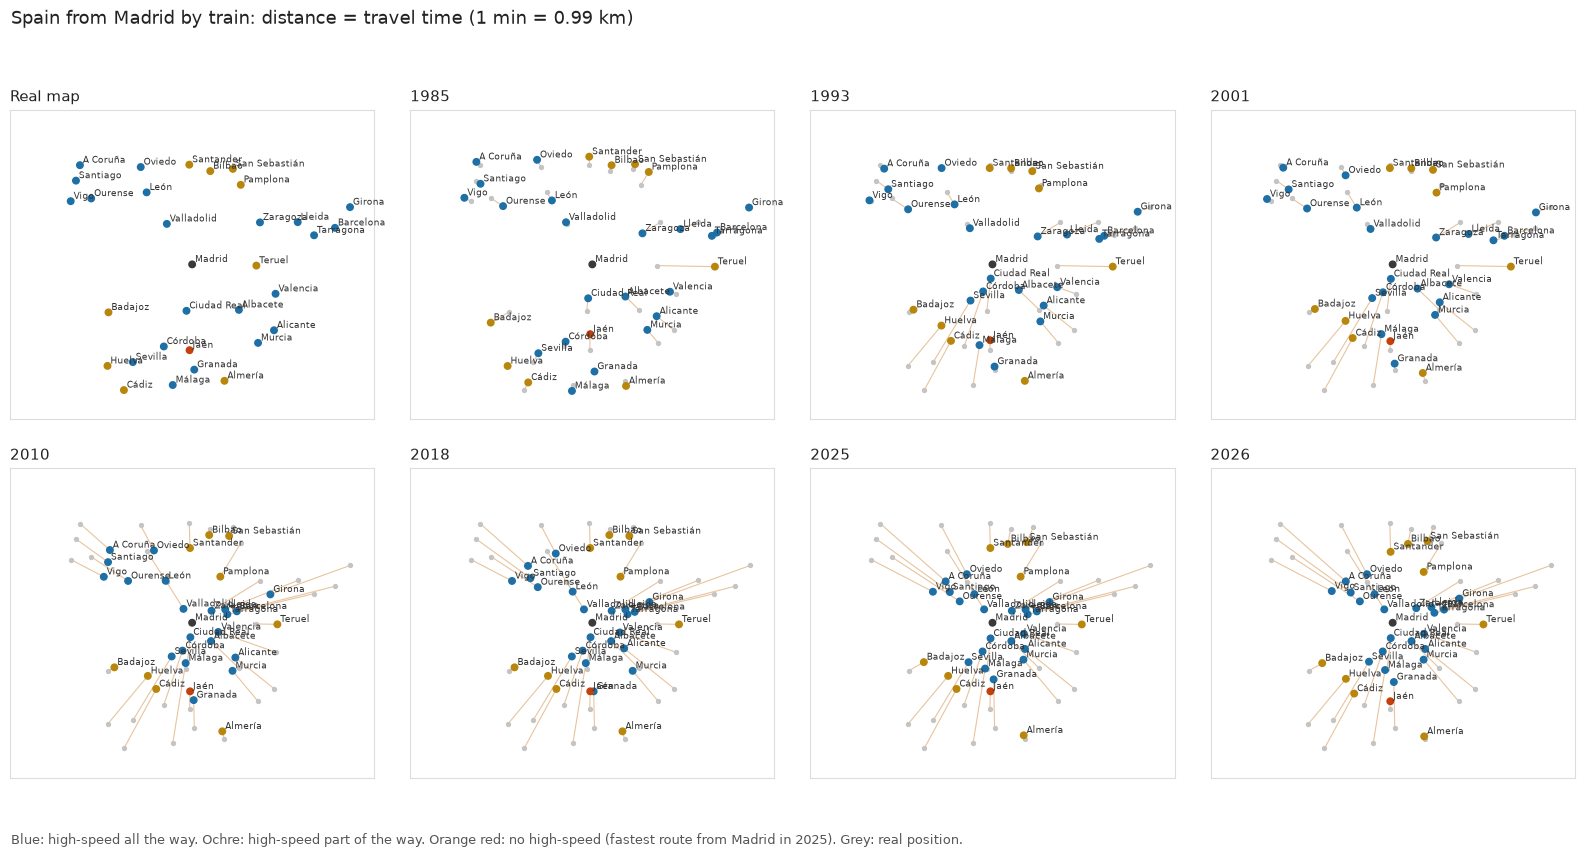

In [8]:
FIG_DIR.mkdir(exist_ok=True)
panels = ["real"] + ERAS
fig, axes = plt.subplots(2, 4, figsize=(16, 8.6))
for ax, era in zip(axes.flat, panels):
    p = madrid[madrid["era"] == (ERAS[0] if era == "real" else era)]
    if era == "real":
        x = p["real_x_km"]
        y = p["real_y_km"]
    else:
        x = p["x_km"]
        y = p["y_km"]
        for x0, y0, x1, y1 in zip(p["real_x_km"], p["real_y_km"], x, y):
            ax.plot([x0, x1], [y0, y1], color=MOVE_COLOUR, lw=0.8, zorder=1)
        ax.scatter(p["real_x_km"], p["real_y_km"], s=8, color=REAL_COLOUR, zorder=2)
    colours = [COLOUR[group[c]] for c in p["city"]]
    ax.scatter(x, y, s=22, c=colours, zorder=3)
    for c, xi, yi in zip(p["city"], x, y):
        ax.text(xi + 10, yi + 8, c, fontsize=6.5, color="#333333")
    ax.set_xlim(-FIG_EXTENT_KM, FIG_EXTENT_KM)
    ax.set_ylim(-FIG_EXTENT_KM * 0.85, FIG_EXTENT_KM * 0.85)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color("#dddddd")
    label = "Real map" if era == "real" else era
    ax.set_title(label, loc="left", fontsize=11, color="#222222")
fig.suptitle(f"Spain from Madrid by train: distance = travel time (1 min = {KM_PER_MIN:.2f} km)", x=0.01, ha="left", fontsize=13, color="#222222")
fig.text(0.01, 0.01, f"Blue: {ACCESS_LABEL['full']}. Ochre: {ACCESS_LABEL['part']}. Orange red: {ACCESS_LABEL['none']} (fastest route from Madrid in 2025). Grey: real position.", fontsize=9, color="#555555")
plt.tight_layout(rect=(0, 0.02, 1, 0.97))
plt.savefig(FIG_DIR / "04timemap.png", dpi=130)
plt.show()

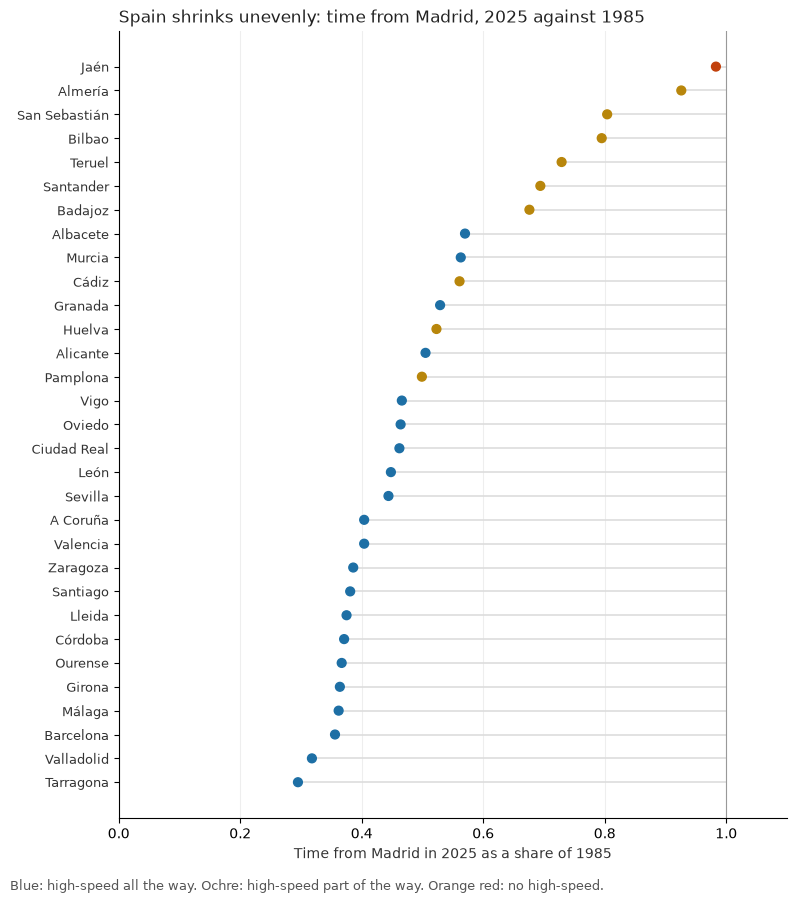

In [9]:
order = story.sort_values(share)
fig, ax = plt.subplots(figsize=(8, 9))
y = np.arange(len(order))
ax.hlines(y, order[share], 1, color="#dddddd", lw=1.2, zorder=1)
ax.scatter(order[share], y, s=40, c=[COLOUR[g] for g in order["access"]], zorder=3)
ax.axvline(1, color="#999999", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(order.index, fontsize=9, color="#333333")
ax.set_xlim(0, 1.1)
ax.set_xlabel(f"Time from Madrid in {STORY_ERA} as a share of {ERAS[0]}", color="#333333")
ax.grid(axis="x", color="#eeeeee")
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_title(f"Spain shrinks unevenly: time from Madrid, {STORY_ERA} against {ERAS[0]}", loc="left", fontsize=12, color="#222222")
fig.text(0.01, 0.005, f"Blue: {ACCESS_LABEL['full']}. Ochre: {ACCESS_LABEL['part']}. Orange red: {ACCESS_LABEL['none']}.", fontsize=9, color="#555555")
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig(FIG_DIR / "04shrink.png", dpi=130)
plt.show()

## 8. Save the positions

In [10]:
out = positions.copy()
for column in ["minutes", "bearing", "x_km", "y_km", "real_x_km", "real_y_km"]:
    out[column] = out[column].round(2)
out.to_csv(CLEAN_DIR / "timemap_positions.csv", index=False, encoding="utf-8")
print(f"saved timemap_positions.csv: {len(out)} rows ({len(ERAS)} eras x {len(names)} centres x {len(names)} cities)")

saved timemap_positions.csv: 7168 rows (7 eras x 32 centres x 32 cities)


___
**END**